# Modèle de Régression Logistique

Ce notebook contient l'implémentation et l'évaluation du modèle de régression logistique pour prédire l'attrition des employés.

La régression logistique est un algorithme de classification supervisée adapté aux problèmes binaires. Dans ce projet, il permet de prédire si un employé risque de quitter l’entreprise (**Attrition = 1**) ou non (**Attrition = 0**) à partir de variables RH préparées.

## Rappel théorique sur la Régression Logistique

La régression logistique est une technique statistique utilisée pour modéliser la probabilité qu’un événement binaire se produise. Contrairement à la régression linéaire, qui prédit une valeur continue, elle prédit une probabilité comprise entre 0 et 1, ensuite convertie en classe à l’aide d’un seuil de décision (souvent 0.5).

Elle repose sur une combinaison linéaire des variables explicatives :

$$
z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n
$$

Cette combinaison est transformée en probabilité grâce à la fonction sigmoïde :

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

La probabilité que l’événement se produise ($y=1$) est alors donnée par :

$$
P(y=1|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n)}}
$$

L’entraînement du modèle consiste à ajuster les coefficients $\beta$ en minimisant une fonction de coût (log-loss / entropie croisée), afin de produire les probabilités les plus cohérentes possibles avec les données observées.

Dans ce projet, la régression logistique est utilisée comme modèle de référence (baseline), car elle est rapide, robuste et interprétable.


## 1. Importation des bibliothèques

Cette étape permet d’importer les bibliothèques nécessaires pour manipuler les données, entraîner le modèle, évaluer ses performances et sauvegarder les résultats.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

**Explication des bibliothèques utilisées :**

`pandas` et `numpy` servent à manipuler les données tabulaires et numériques.  
`matplotlib` et `seaborn` permettent de visualiser les résultats (matrice de confusion, courbe ROC).  
`scikit-learn` fournit les outils de séparation des données, d’entraînement et d’évaluation du modèle.  
`pickle` permet de sauvegarder le modèle et les résultats pour une réutilisation ultérieure.

## 2. Chargement des données préparées

On charge le jeu de données prétraité, puis on sépare les variables explicatives (`X`) et la variable cible (`y`).


In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


**Explication :**

La colonne `Attrition` correspond à la variable cible à prédire.  
La colonne `EmployeeID` est supprimée car c’est un identifiant unique, sans utilité prédictive.

L’affichage de la distribution de la cible permet de vérifier si les classes sont équilibrées ou non, ce qui est important pour l’interprétation des résultats.


## 3. Séparation des données

Les données sont divisées en un ensemble d’entraînement et un ensemble de test afin d’évaluer le modèle sur des données qu’il n’a jamais vues.

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


**Explication :**

L’ensemble d’entraînement (70 %) est utilisé pour apprendre les paramètres du modèle.  
L’ensemble de test (30 %) est utilisé pour mesurer la capacité de généralisation du modèle.

Le paramètre `random_state=42` garantit la reproductibilité de la séparation.

## 4. Entraînement du modèle de Régression Logistique

La régression logistique est une méthode statistique utilisée pour résoudre des problèmes de classification binaire. Elle repose sur la fonction sigmoïde, qui transforme une combinaison linéaire des variables explicatives en une probabilité, permettant ainsi de classer les observations dans l'une des deux catégories.

In [4]:
# Initialisation et entraînement du modèle
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


**Explication :**

`max_iter=1000` augmente le nombre maximal d’itérations pour assurer la convergence du modèle.  
`random_state=42` permet d’obtenir des résultats reproductibles.

L’appel à `fit(X_train, y_train)` lance l’apprentissage du modèle sur les données d’entraînement.

## 5. Prédictions

Une fois le modèle entraîné, on génère des prédictions sur l’ensemble de test, à la fois sous forme de classes et de probabilités.

In [ ]:
# Prédictions sur l'ensemble de test
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


**Explication :**

`predict()` retourne la classe prédite (0 ou 1).  
`predict_proba()` retourne la probabilité associée à chaque classe.

Ici, `[:, 1]` permet de récupérer la probabilité de la classe positive (`Attrition = 1`), utile pour le calcul de l’AUC et la courbe ROC.

## 6. Évaluation du modèle

L’évaluation repose sur plusieurs métriques complémentaires afin d’analyser les performances du modèle sous différents angles.

### 6.1 Matrice de confusion

La matrice de confusion compare les classes réelles et les classes prédites, et permet d’identifier les bonnes et mauvaises classifications.

Matrice de Confusion (Régression Logistique) :
 [[1077   38]
 [ 149   59]]


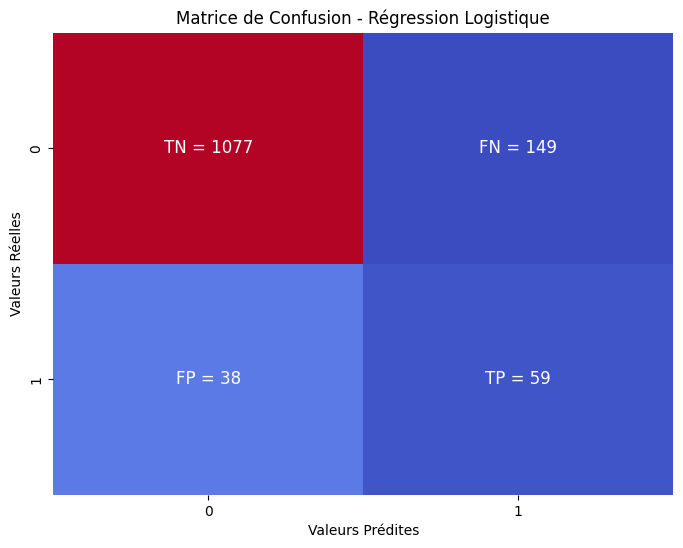

In [ ]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (Régression Logistique) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - Régression Logistique")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

**Explication :**

**TN (True Negatives)** : employés correctement prédits comme non-partants  
**TP (True Positives)** : employés correctement prédits comme partants  
**FP (False Positives)** : employés prédits comme partants alors qu’ils restent  
**FN (False Negatives)** : employés prédits comme non-partants alors qu’ils quittent réellement l’entreprise

Dans un contexte RH, les **FN** sont souvent critiques car ils correspondent à des départs non anticipés.

### 6.2 Rapport de classification

Le rapport de classification fournit des métriques détaillées par classe, comme la précision, le rappel et le F1-score.

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (Régression Logistique) :\n", class_report)

Rapport de Classification (Régression Logistique) :
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1115
           1       0.61      0.28      0.39       208

    accuracy                           0.86      1323
   macro avg       0.74      0.62      0.65      1323
weighted avg       0.84      0.86      0.84      1323



**Explication :**

**Précision (Precision)** : parmi les prédictions positives, proportion de celles qui sont correctes.  
**Rappel (Recall)** : parmi les cas réellement positifs, proportion détectée par le modèle.  
**F1-score** : compromis entre précision et rappel.  
**Support** : nombre d’observations de chaque classe.

Pour l’attrition, le rappel de la classe positive est particulièrement important si l’objectif est d’anticiper les départs.

### 6.3 Score AUC-ROC

Le score AUC-ROC mesure la capacité du modèle à distinguer les deux classes sur l’ensemble des seuils possibles.

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (Régression Logistique) : {roc_auc:.4f}")

AUC-ROC (Régression Logistique) : 0.8024


**Explication :**

L’AUC varie entre 0 et 1.

Une valeur proche de **0.5** indique un modèle peu performant (proche du hasard).  
Une valeur plus élevée indique une meilleure capacité de discrimination entre employés partants et non-partants.

### 6.4 Courbe ROC

La courbe ROC permet de visualiser la performance du modèle en fonction de différents seuils de décision.

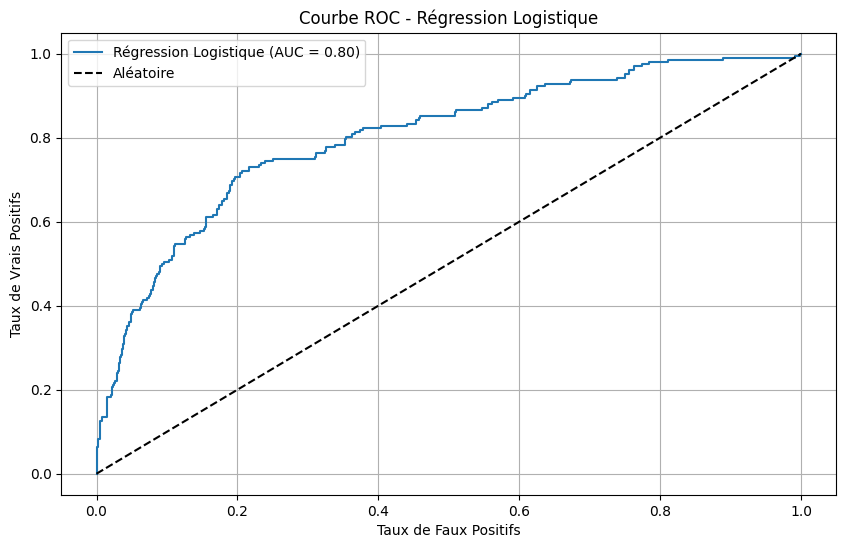

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Régression Logistique (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - Régression Logistique")
plt.legend()
plt.grid(True)
plt.show()

**Explication :**

La courbe ROC met en relation le **taux de faux positifs (FPR)** et le **taux de vrais positifs (TPR)**.

Plus la courbe est proche du coin supérieur gauche, meilleure est la performance du modèle.  
La diagonale représente un classifieur aléatoire.

## 7. Sauvegarde du modèle et des résultats

Cette étape permet de conserver le modèle entraîné et les résultats d’évaluation pour les réutiliser plus tard, notamment dans une comparaison avec d’autres algorithmes.

In [10]:
# Sauvegarde du modèle
with open('Data/logistic_regression_model.pkl', 'wb') as f:
    pickle.dump(log_reg, f)

# Sauvegarde des résultats
results = {
    'model_name': 'Logistic Regression',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix
}

with open('Data/logistic_regression_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


**Explication :**

La sauvegarde du modèle évite de le réentraîner à chaque fois.  
La sauvegarde des résultats permet de centraliser les performances et de les comparer facilement avec d’autres modèles.

## Résumé

Ce notebook a permis de :

1. Charger les données préparées
2. Entraîner un modèle de régression logistique
3. Générer des prédictions (classes et probabilités)
4. Évaluer les performances avec plusieurs métriques (matrice de confusion, rapport de classification, AUC-ROC, courbe ROC)
5. Sauvegarder le modèle et les résultats pour une comparaison ultérieure

La régression logistique constitue ici un modèle de référence simple, rapide et interprétable pour la prédiction de l’attrition des employés.